# Simple SPH with gravity

In this example, we want to perform the simplest SPH operation: calculate the density field based on the underlying particle distribution. Assuming constant internal energy, we also calculate pressure. We let particles interact via short-range gravity, i.e., we neglect long-range contributions. This is because the interaction is calculated based on the local and active sets -- see docs.

In [291]:
import os

import peano4
import peano4.dastgen2
import peano4.toolbox
import peano4.toolbox.particles
import dastgen2

In [292]:
# If we want to start a project from scratch, we may want to remove some of the generated code
!make clean; rm -r actions/ vertexdata/ repositories/ globaldata/ celldata/ observers/ 

project = peano4.Project( ["examples", "particles"], "sph-simple-multiscale-particle-interaction", "." )

rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertRandomParticlesIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/CalcDensities.o ./observers/CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleAMR3.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/CalcDensities.o ./observers/Move2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Move2peano4_toolbox_particles_ParticleParticleInteraction1.o ./observers/Move2peano4_toolbox_particles_

## Prepare code

Peano's API does not know which settings to use on the present system. To make it copy/clone the settings identified by ./configure, we ask it to parse the generated configuration scripts. 

In [293]:
#build_mode = peano4.output.CompileMode.Asserts
build_mode = peano4.output.CompileMode.Release
project.output.makefile.parse_configure_script_outcome( "../../.." )
project.output.makefile.set_mode( build_mode )

parse configure outcome ../../../config.log to extract configure settings
found the configure call info   $ ./configure --with-mpi=mpicxx --with-multithreading=omp CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops CC=gcc CXX=g++ FC=gfortran --enable-loadbalancing --enable-exahype --enable-particles --enable-blockstructured

parse configure outcome ../../../src/Makefile to extract compile settings
add CXX=mpicxx
add CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops
add CXXFLAGS_PEANO_2D_ASSERTS=-DDimensions=2 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_2D_DEBUG=-DDimensions=2 -DPeanoDebug=4 -g3 -O0
add CXXFLAGS_PEANO_2D_RELEASE=-DDimensions=2 -DPeanoDebug=0
add CXXFLAGS_PEANO_2D_STATS=-DDimensions=2 -DPeanoDebug=0 -DTrackStatistics
add CXXFLAGS_PEANO_2D_TRACE=-DDimensions=2 -DPeanoDebug=1 -g3
add CXXFLAGS_PEANO_3D_ASSERTS=-DDimensions=3 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_3D_DEBUG=-DDimensions=3 -DPeanoDebug=4 -g3

## Model the particle

We create the particle through the toolbox. A particle by definition has a position, so we just need to add everything else for SPH:
- Velocity array
- Acceleration array
- Mass
- Density
- Pressure
- Internal Energy (U)
- Time derivative of internal energy (U')
- Kernel smoothing length

We add a marker to indicate the next calculation step required for a particle so we don't perform the same step on a particle twice in a row.

We also add an array to store the the new position of a particle after a timestep is completed. We will use this to move the particle at the start of the subsequent timestep.

In [294]:
particle = peano4.toolbox.particles.Particle("Particle")

# Define properties
v_attr = peano4.dastgen2.Peano4DoubleArray("v","Dimensions")
a_attr = peano4.dastgen2.Peano4DoubleArray("a","Dimensions")
mass_attr    = dastgen2.attributes.Double("mass")
density_attr = dastgen2.attributes.Double("density")
pressure_attr= dastgen2.attributes.Double("pressure")
u_attr       = dastgen2.attributes.Double("u")
uDash_attr   = dastgen2.attributes.Double("uDash")
smoothL_attr = dastgen2.attributes.Double("smoothingLength")
#step_attr    = dastgen2.attributes.Enumeration("step", ["calcDensity", "calcAccel", "move"]) # Check!
step_attr    = dastgen2.attributes.Enumeration("step", ["calcDensity", "Move"]) # Check!
#newX_attr    = peano4.dastgen2.Peano4DoubleArray("newX", "Dimensions") # updated copy of X

# Add particle properties
particle.data.add_attribute(v_attr)
particle.data.add_attribute(a_attr)
particle.data.add_attribute(mass_attr)
particle.data.add_attribute(density_attr)
particle.data.add_attribute(pressure_attr)
particle.data.add_attribute(u_attr)
particle.data.add_attribute(uDash_attr)
particle.data.add_attribute(smoothL_attr)
particle.data.add_attribute(step_attr)
#particle.data.add_attribute(newX_attr)

particles = peano4.toolbox.particles.ParticleSet(particle)

This particle has to be added to the project. This way the project knows that we are working with this guy. We associate the particle with the vertices, as we work with the pidt (particle in dual tree) algorithm. 

In [295]:
project.datamodel.add_global_object(particle)
project.datamodel.add_vertex       (particles)

## Export global SPH constants

There are plenty of constant simulation paramaters to specify for our SPH simulation - we do that here. 

In [296]:
dimensions = 2
project.output.makefile.set_dimension(dimensions)

In [297]:
5/3

1.6666666666666667

In [298]:
from numpy import pi

# SPH constants
GAMMA = str(5/3)
DYNAMIC_VISCOSITY     = "0.00001"
CUBIC_SPLINE_SIGMA_2D = str(10/(7*pi))
CUBIC_SPLINE_SIGMA_3D = str(1/pi)
TARGET_PARTICLE_SIZE  = "0.01"
ENERGY_SPIKE = "0.1"
SPIKE_RADIUS = "0.08"
REST_DENSITY = "1"
INITIAL_H = "0.02"

project.constants.export_const_with_type("GAMMA", GAMMA, "double")
project.constants.export_const_with_type("DYNAMIC_VISCOSITY", DYNAMIC_VISCOSITY, "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA_2D", CUBIC_SPLINE_SIGMA_2D, "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA_3D", CUBIC_SPLINE_SIGMA_3D, "double")
project.constants.export_const_with_type("TARGET_PARTICLE_SIZE", TARGET_PARTICLE_SIZE, "double")
project.constants.export_const_with_type("ENERGY_SPIKE", ENERGY_SPIKE, "double")
project.constants.export_const_with_type("SPIKE_RADIUS", SPIKE_RADIUS, "double")
project.constants.export_const_with_type("REST_DENSITY", REST_DENSITY, "double")
project.constants.export_const_with_type("INITIAL_H", INITIAL_H, "double")

#if dimensions==2:
#  DOMAIN_OFFSET = "{0.0, 0.0}"
#  DOMAIN_SIZE = "{1.0, 1.0}"
#  EXPLOSION_CENTRE = "{0.5, 0.5}"
#else:
#  DOMAIN_OFFSET = "{0.0, 0.0, 0.0}"
#  DOMAIN_SIZE = "{1.0, 1.0, 1.0}"
#  EXPLOSION_CENTRE = "{0.5, 0.5, 0.5}"

#project.constants.export_const_with_type("DOMAIN_OFFSET", DOMAIN_OFFSET, "auto")
#project.constants.export_const_with_type("DOMAIN_SIZE", DOMAIN_SIZE, "auto")
#project.constants.export_const_with_type("EXPLOSION_CENTRE", EXPLOSION_CENTRE, "auto")

## Model the setup phases

The setup remains almost unchanged. I give all particles a biased random initial velocity. This will introduce an adaptive mesh, as particles will cluster in the bottom left part of the 2d domain.

In [299]:
mesh_size = 0.2

particle_tree_analysis = peano4.toolbox.particles.ParticleTreeAnalysis(particles)
project.datamodel.add_cell(particle_tree_analysis.cell_marker)   # read docu of ParticleTreeAnalysis

create_grid = peano4.solversteps.Step( name="CreateGrid", add_user_defined_actions=False )
create_grid.add_action_set( peano4.toolbox.CreateRegularGrid(mesh_size) )
create_grid.use_vertex(particles)
create_grid.use_cell(particle_tree_analysis.cell_marker)
project.solversteps.add_step(create_grid)

## Initial conditions for particles

In [300]:
initialisation_snippet = """
 
 particle->setCutOffRadius(0.05);

 // We will set random velocities for (v_x, v_y)
 particle->setV( 0, 1E0*(0.5 -((double) rand() / (RAND_MAX))) );
 particle->setV( 1, 1E0*(0.5 -((double) rand() / (RAND_MAX))) );
 
 //particle->setV( 0, 0.0);
 //particle->setV( 1, 0.0);
 
 // For SPH, we also want to initialise a few more variables:
 particle->setDensity (1.0);        
 particle->setU       (1.E-2);
 particle->setPressure(1.0);
 particle->setMass    (1E0);        
 particle->setSmoothingLength(0.05);

"""

init_setup = peano4.solversteps.Step( name="Init", add_user_defined_actions=False )
init_setup.use_vertex(particles)
init_setup.use_cell(particle_tree_analysis.cell_marker)
init_setup.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
init_setup.add_action_set( peano4.toolbox.particles.InsertRandomParticlesIntoUnrefinedCells(
  particle_set=particles,
  average_distance_between_particles=mesh_size/10,
#  average_distance_between_particles=mesh_size/20,
  initialisation_call=initialisation_snippet,
  noise=True ))
init_setup.add_action_set( particle_tree_analysis )
project.solversteps.add_step(init_setup)

## Particle behaviour

We stick to exactly the same particle behaviour from a code point of view. However, we use a pre-manufactured toolbox  into which we inject the actual code. The important fact here is that we now do not simply rely on the particles of the adjacent vertices of a cell. Instead, we work with active and local particle sets.

ls: cannot access '../../python/peano4/toolbox/particles': No such file or directory


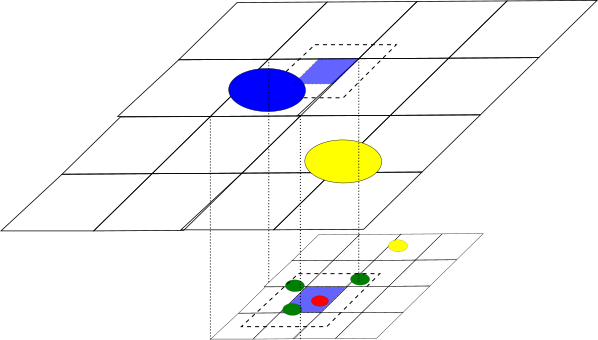

In [301]:
from IPython.display import Image
!ls ../../python/peano4/toolbox/particles
Image("../../../python/peano4/toolbox/particles/dependency_sets.png")

To understand what the individual particles in the sketch above are supposed to mean and how they are maintained and exposed to the user, please consult the documentation of the ParticleParticleInteraction class in the Python toolbox directory. It contains a lot explanations.

## Write the actual particle movement (the move step below)

We will implement the actual particle movement ourselves. For this, we have asked Move to be an action set with manual user code, and indeed we get a Move class in the actions subdirectory once we have triggered the build process. This is, same as main, an empty blueprint. We can alter it, and Peano won't overwrite it anymore after that. If we delete it, the API will regenerate it however. The current example has already a pre-prepared Move, so it won't be empty, but you might want to delete it and regenerate it to see what you get in the first place.

Here's what I changed in the Move class: Move is a standard class which defines an action set: There's a fixed number of callbacks that are invoked by Peano, and we can use these to inject behaviour. I only alter (or plug into) three actions: 

### First access to vertex

Particles are associated to vertices. So when I hit a vertex the first time, I also hit the particles associated with it for the first time. I run over them, and set their status to NotMovedYet:

     for (auto& p: fineGridVertexParticleSet) {
       p->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
     }

### Hit cell

When I hit a cell, I actually evaluate the "forces" and alter the particles' velocities. I do this only for the particles that reside within the cell, as I know that a neighbouring cell will either be hit after or before the current one. If I modified all particles associated with the 2^d vertices of a cell, I'd modify particles multiple times. 

Please note that I only change the particles' attributes. I do not change their position. That means, the logical topology of all data, i.e. how they are assigned to vertices remains valid and intact. This means that we don't care how Peano runs through the cells. All data remains valid.

Please see touchCellFirstTime() for details.


### Last access to vertex

When I hit a vertex for the last time, I know that all 2^d adjacent cells have been "visited". Therefore, I can now finally update the vertex position. The vertex won't be used by neighbouring cells anymore and we are fine. Again, I do this only for particles that haven't moved yet. Otherwise we might move a particle, it ends up around another vertex that we haven't processed yet and then it is moved again.

    const double timeStepSize = 0.0001;
    for (auto& p: fineGridVertexParticleSet) {
      if (
        p->getMoveState()!=globaldata::Particle::MoveState::Moved
        and
        p->getParallelState()==globaldata::Particle::ParallelState::Local
      ) {
        p->setX( p->getX() + timeStepSize * p->getV() );
        for (int d=0; d<Dimensions; d++) {
          if ( p->getX()(d)<0.0 ) {
            p->setV(d, std::abs(p->getV()(d)));
          }
          if ( p->getX()(d)>1.0 ) {
            p->setV(d, -std::abs(p->getV()(d)));
          }
        }
      }
      p->setMoveState( globaldata::Particle::MoveState::Moved );
    }

You see, we also add reflecting boundary conditions.

## Calculate densities at particles (density loop)

In the first phase of a timestep we move particles to their new positions calculated in the previous timestep.

For each particle we also calculate the fluid density at its position based on the positions and masses of the particles in its local neighbourhood.

From the density and the internal energy we calculate the fluid pressure at the particle's position.

In [302]:
calc_densities = peano4.solversteps.Step( "CalcDensities" )
calc_densities.use_vertex(particles)
calc_densities.use_cell(particle_tree_analysis.cell_marker)
calc_densities.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """
// The used action set does the run over the local set and the active set. So we
// simply have to feed in the particle-particle interaction potential.
 
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  //const double dist = tarch::la::norm2(distVec);
 
  const double h = localParticle->getSmoothingLength();
  const double dist = tarch::la::norm2( localParticle->getX() - activeParticle->getX() );
  if ( dist < localParticle->getCutOffRadius() ) {
    const double q = dist / h;
    
    // Density calculation
    // Default SPH kernel (cubic spline)
    double W = CUBIC_SPLINE_SIGMA_2D / (h*h);   // 2D kernel normalization
    //double W = CUBIC_SPLINE_SIGMA_3D / (h*h*h); // 3D kernel normalization
    
    if (q >= 2) {
      W *= 0;
    } else if (q >= 1) {
      W *= (0.25 * (2 - q)*(2 - q)*(2 - q));
    } else {
      W *= (1 - 1.5*q*q*(1 - q/2));
    }

    double densityNgbs = activeParticle->getMass() * W;
    localParticle->setDensity( localParticle-> getDensity() + densityNgbs );
  }
"""

touch_particle_last_time_compute_kernel = """
  // If we assumed U is conserved, then it is OK to calculate the pressure here.
  double eosPressure = localParticle->getDensity() * localParticle->getU() * (GAMMA - 1); // EoS
  localParticle->setPressure( (eosPressure < 0) ? 0 : eosPressure );
"""

touch_particle_first_time_compute_kernel = """
  localParticle->setDensity (0.0);   // we'll accumulate the data throughout mesh/particle traversal
"""

calc_densities.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes='#include "Constants.h" '
))
calc_densities.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities)

## Move step (force loop)

Each particle has its acceleration calculated using the densities, pressures and velocities of its neighbours.

We also calculate the time derivative of the internal energy.

In [303]:
move_particles = peano4.solversteps.Step( "Move", add_user_defined_actions=False )
move_particles.use_vertex(particles)
move_particles.use_cell(particle_tree_analysis.cell_marker)
move_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
move_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  tarch::la::Vector<Dimensions,double> accelHydro(0.0);
  const double dist = tarch::la::norm2(distVec);

  // Hydrodynamics:
  // Here we calculate the acceleration due to pressure forces according to the Euler Equation.
  
  if ( tarch::la::greater( dist,0.0 ) ) {
    if ( dist < localParticle->getCutOffRadius() ) {
    
      const double h = localParticle->getSmoothingLength();
      const double q = dist / h;

      const double massNgbs = activeParticle->getMass();
      const double POverRhoSquared     = localParticle ->getPressure()/(localParticle ->getDensity() * localParticle ->getDensity());
      const double POverRhoSquaredNgbs = activeParticle->getPressure()/(activeParticle->getDensity() * activeParticle->getDensity());

      // Default SPH kernel (cubic spline)
      double delW = CUBIC_SPLINE_SIGMA_2D / (h*h);   // 2D kernel normalization
      //double delW = CUBIC_SPLINE_SIGMA_3D / (h*h*h); // 3D kernel normalization

      if (q >= 2) {
        delW *= 0;
      } else if (q >= 1) {
        delW *= (-0.75 * ((2 - q)*(2 - q)));
      } else {
        delW *= (0.75*q * (3*q - 4));
      }

//      tarch::la::Vector<Dimensions,double> gradW = (delW / h) * (distVec / dist); // gives buggy result.
      tarch::la::Vector<Dimensions,double> gradW = delW*distVec/dist/h;
           
      // Update specific internal energy -- not used for now since we assume U is conserved
//      const double u = POverRhoSquared * massNgbs * tarch::la::dot( (localParticle->getV() - activeParticle->getV()), gradW );
//      const double u = massNgbs*tarch::la::dot( (localParticle->getV() - activeParticle->getV()), delW*distVec/dist/h );
//      const double u = (GAMMA-1)/localParticle->getDensity() * massNgbs*tarch::la::dot( 
//                       (localParticle->getV() - activeParticle->getV()) , delW*distVec/dist/h );
//      localParticle->setU( localParticle-> getU() - 0.001 * u );
    
      // Update velocity
//      accelHydro = - massNgbs*( POverRhoSquared + POverRhoSquaredNgbs )*gradW; // gives buggy results.
      accelHydro = - 1E-5*massNgbs*gradW; // 
      localParticle->setV( localParticle-> getV() + 0.001 * accelHydro );
      }
  }
  
  
  // Add gravity:
  // Here we use the gravitational interaction among particles, i.e. the N-body system. Note that we only
  // loop over local + active sets, not the N^2 particles, hence we neglecet long-range contributions.
  // To avoid the 1/r^2 divergence due to particles being too close, we use a softening length parameter.
  
  const double SoftLen = 0.02;
  const double G_Newton= 1E-2;  // We can regulate the strength of gravity. For physical results we should use correct units.

  if ( tarch::la::greater( dist,0.0 ) ) {
    const double massLoc = localParticle ->getMass();
    const double massAct = activeParticle->getMass();
    
    double forcePart = -G_Newton*massLoc*massAct/ std::pow( dist*dist+SoftLen*SoftLen,1.5 );
    double accelGrav = forcePart/massLoc;
    
    // Update velocity
    localParticle->setV( localParticle->getV() + 0.001 * accelGrav*distVec );
  }
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  const double timeStepSize = 0.0001;
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
  ) { 
    // Update position
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
    for (int d=0; d<Dimensions; d++) {
      if ( localParticle->getX()(d)<0.0 ) {
        localParticle->setV( d, std::abs(localParticle->getV()(d)) );
      }
      if ( localParticle->getX()(d)>1.0 ) {
        localParticle->setV( d,-std::abs(localParticle->getV()(d)) );
      }
    }
    localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
  }
  
  // Update Pressure once both density and internal energy are known.
  // This can be done in Density step if U is conserved.
//  double eosPressure = localParticle->getDensity() * localParticle->getU() * (GAMMA - 1); // EoS
//  localParticle->setPressure( (eosPressure < 0) ? 0 : eosPressure );
""",
  additional_includes='#include "Constants.h" '
  ))
move_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
move_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(move_particles)

### Plots setup

I will have to plot the outcome (or any snapshot). With particles, each of my dumps produces two types of files: particle data and mesh data. For the mesh, I rely on the toolbox's grid plotting. The plot is the step where we don't need the AMR criterion - the particles don't move here after all. We however run the tree analysis, so it is up-to-date for the next step.

In [304]:
# Particle plotter
particle_plotter = peano4.toolbox.particles.PlotParticlesInVTKFormat( "particles", particles, time_stamp_evaluation=peano4.toolbox.particles.PlotParticlesInVTKFormat.CountTimeSteps )
particle_plotter.add_attribute_to_plot(v_attr       , 1)
particle_plotter.add_attribute_to_plot(density_attr , 1)
particle_plotter.add_attribute_to_plot(pressure_attr, 1)
particle_plotter.add_attribute_to_plot(u_attr       , 1)
particle_plotter.add_attribute_to_plot(mass_attr    , 1)
particle_plotter.add_attribute_to_plot(smoothL_attr , 1)


# Solution plotter
print_solution = peano4.solversteps.Step( "Plot", add_user_defined_actions=False )
print_solution.use_vertex(particles)
print_solution.use_cell(particle_tree_analysis.cell_marker)
print_solution.add_action_set( particle_tree_analysis )
print_solution.add_action_set( peano4.toolbox.PlotGridInPeanoBlockFormat( filename="grid", time_stamp_evaluation=peano4.toolbox.PlotGridInPeanoBlockFormat.CountTimeSteps ) )
print_solution.add_action_set( particle_plotter )

project.solversteps.add_step(print_solution)

## Generate the actual C++ code

Next, we generate the actual Peano 4 C++ code:

In [305]:
project.generate()

generate all code ...
user has to modify class CalcDensities in actions directory manually 
generated sph-simple-multiscale-particle-interaction-main.cpp
write ./Makefile
./vertexdata/ParticleSet.h written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristian/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.h)
./vertexdata/ParticleSet.cpp written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristian/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.cpp)
./repositories/DataRepository.h written by TemplatedHeaderImplementationFilePair.py
./repositories/DataRepository.cpp written by TemplatedHeaderImplementationFilePair.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.h written by ActionSet.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.cpp written by ActionSet.py
write ././observers/CreateGrid.h
././observers/CreateGrid.cpp written by Observer.py
././observers/Init2peano4_toolbo

## Write the main

This time, the main is slightly more sophisticated. We continue to set up the grid as before, but then we always run 10 iterations of the Move, i.e. we do 10 time steps, and then we plot. The whole sequence is repeated a couple of times. Have a look into the main file in the repo to see the whole snippet:

    ...
    for (int i=0; i<100; i++) {
      for (int j=0; j<10; j++) {
        examples::particles::observers::Move moveObserver;
        peano4::parallel::SpacetreeSet::getInstance().traverse(moveObserver);
      }
      logInfo( "main()", "plot" )
      examples::particles::observers::Plot plotTimeStepObserver;
      peano4::parallel::SpacetreeSet::getInstance().traverse(plotTimeStepObserver);
    }
    
Do not forget to include the generated header files, e.g., 
    
    //
    // =================
    // inserted manually
    // =================
    //
    #include "observers/CreateGrid.h"
    #include "observers/Init.h"
    #include "observers/Plot.h"
    #include "observers/Move.h"


## Build the code

In [306]:
project.build()

clean up project ...
clean complete
start to compile with concurrency level of 4 ...
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o celldata/ParticleSetCellStatistics.o celldata/ParticleSetCellStatistics.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o vertexdata/ParticleSet.o vertexdata/ParticleSet.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o globaldata/Particle.o globaldata/Particle.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o repositories/DataRepository.o repositories/DataRepository.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDeb

## Run code

In [307]:
output_files = [ f for f in os.listdir(".") if f.endswith(".peano-patch-file") or f.endswith(".vtu") or f.endswith(".pvd") ]
for f in output_files:
  os.remove(f)

In [ ]:
# success = project.run( args=["--threads", "1"], prefix=["mpirun", "-n", "1"] )
!./peano4

Peano 4 (C) www.peano-framework.org 
build: 2d, with mpi (1 ranks), omp (4 threads)
 581578169    00:00:00     rank:0       core:0       error        peano4::parallel::Node::init()                          was not able to query what the maximum tag value is (file:peano4/parallel/Node.cpp,line:92)
 590622465    00:00:00     rank:0       core:0       info         ::::main()                                              run a grid construction step and insert particles
 590617755    00:00:00     rank:0       core:2       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Refine,offset=[-2.99616e+307,-2.99616e+307],width=[8.98847e+307,8.98847e+307],h=[0.2,0.2])
 591983571    00:00:00     rank:0       core:0       info         ::::main()                                              run a grid construction step and insert particles
 591922448    00:00:00     rank:0       core:3       info         peano4::grid::Spacetree::travers

 1310408671   00:00:01     rank:0       core:1       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9043/2531/0/0/0 on tree 0
 1310973007   00:00:01     rank:0       core:2       info         ::::main()                                              run timestep
 1359555084   00:00:01     rank:0       core:1       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9043/2531/0/0/0 on tree 0
 1433717641   00:00:01     rank:0       core:1       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9043/2531/0/0/0 on tree 0
 143

 2827439547   00:00:02     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=1/0/0/9051/2531/0/0/0 on tree 0
 2902116797   00:00:02     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9053/2531/0/0/0 on tree 0
 2902673033   00:00:02     rank:0       core:1       info         ::::main()                                              run timestep
 2952879969   00:00:02     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=1/0/0/9052/2531/0/0/0 on tr

 4334299077   00:00:04     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9071/2531/0/0/0 on tree 0
 4334873636   00:00:04     rank:0       core:2       info         ::::main()                                              run timestep
 4386599052   00:00:04     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=2/0/0/9073/2531/0/0/0 on tree 0
 4465813689   00:00:04     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9073/2531/0/0/0 on tree 0
 446

 5800696244   00:00:05     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=2/1/1/9086/2530/0/0/0 on tree 0
 5875586686   00:00:05     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9091/2531/0/0/0 on tree 0
 5876157718   00:00:05     rank:0       core:0       info         ::::main()                                              plot        
 5902317518   00:00:05     rank:0       core:0       info         ::::main()                                              run timestep
 5952516059   00:00:05     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGr

 7392972128   00:00:07     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9134/2531/0/0/0 on tree 0
 7393524505   00:00:07     rank:0       core:1       info         ::::main()                                              run timestep
 7449060094   00:00:07     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=2/2/2/9137/2531/0/0/0 on tree 0
 7530008726   00:00:07     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9136/2531/0/0/0 on tree 0
 753

... (106 outputs left out)

 267905142170 00:04:27     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9699/2379/152/0/0 on tree 0
 267905666388 00:04:27     rank:0       core:3       info         ::::main()                                              run timestep
 267905611999 00:04:27     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got three grid control events: (refinementControl=Erase,offset=[0,0.888889],width=[0.111111,0.111111],h=[0.111111,0.111111]), (refinementControl=Erase,offset=[0.888889,0.222222],width=[0.111111,0.222222],h=[0.111111,0.111111]) and (refinementControl=Erase,offset=[0.111111,0],width=[0.111111,0.111111],h=[0.111111,0.111111])
 268034250174 00:04:28     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_parti

 270417615405 00:04:30     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9683/2369/162/0/0 on tree 0
 270418206810 00:04:30     rank:0       core:3       info         ::::main()                                              run timestep
 270418138722 00:04:30     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got 4 grid control events
 270546640547 00:04:30     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=19/18/18/9688/2362/166/4/0 on tree 0
 270547042060 00:04:30     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got 4 grid 

 272643843985 00:04:32     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=14/26/26/9676/2355/169/1/0 on tree 0
 272644348679 00:04:32     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got three grid control events: (refinementControl=Erase,offset=[0.777778,0.333333],width=[0.111111,0.111111],h=[0.111111,0.111111]), (refinementControl=Erase,offset=[0.888889,0.222222],width=[0.111111,0.222222],h=[0.111111,0.111111]) and (refinementControl=Erase,offset=[0.111111,0],width=[0.111111,0.111111],h=[0.111111,0.111111])
 272853396340 00:04:32     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplica

 274629022458 00:04:34     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation0::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9655/2354/177/0/0 on tree 0
 274629537067 00:04:34     rank:0       core:3       info         ::::main()                                              run timestep
 274629466317 00:04:34     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got three grid control events: (refinementControl=Erase,offset=[0.777778,0.333333],width=[0.111111,0.111111],h=[0.111111,0.111111]), (refinementControl=Erase,offset=[0.888889,0.222222],width=[0.111111,0.222222],h=[0.111111,0.111111]) and (refinementControl=Erase,offset=[0.111111,0],width=[0.111111,0.111111],h=[0.111111,0.111111])
 274760218648 00:04:34     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbo

# Wrap-up


In [ ]:
0.0177019*0.666667*1.24983

## 